# Pet Breed Classifier
Classifying 37 cat and dog breeds from photos using transfer learning with a pretrained ResNet18 in PyTorch.

## Load and Prepare Data
Oxford-IIIT Pets dataset, with images resized to 224x224 and normalized to match what the pretrained model expects.

In [22]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("using:", device)

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

train_data = datasets.OxfordIIITPet(root="data", split="trainval", download=True, transform=transform)
test_data = datasets.OxfordIIITPet(root="data", split="test", download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32)


print(len(train_data), len(test_data))
print(train_data.classes[:5])

using: cuda
3680 3669
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


## Load the Pretrained Model
ResNet18 with all layers frozen, and a new final layer that outputs 37 breeds. Only 18,981 of 11,195,493 parameters are trained.

In [23]:
from torchvision import models
import torch.nn as nn

print("using: ", device )

model = models.resnet18(weights= models.ResNet18_Weights.DEFAULT)

for param in model.parameters():
  param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 37)
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

print(f"trainable parameters: {trainable:,} out of {total:,}")




using:  cuda
trainable parameters: 18,981 out of 11,195,493


## Training
Training only the new final layer for 5 epochs with Adam on a Colab GPU.

In [24]:
from torch.types import Device
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001 )

epochs = 5

for epoch in range(epochs):
  total_loss = 0
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)


      predictions = model(images)
      loss = criterion(predictions, labels)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      total_loss += loss.item()


  print(f"epoch {epoch+ 1 }, avarage loss: {total_loss / len(train_loader):.4f}")

epoch 1, avarage loss: 1.9365
epoch 2, avarage loss: 0.7287
epoch 3, avarage loss: 0.5050
epoch 4, avarage loss: 0.4094
epoch 5, avarage loss: 0.3319


## Evaluating the Model
Accuracy on all 3,669 unseen test photos.

In [25]:
model.eval()
correct = 0

with torch.no_grad():
  for images, labels in test_loader:
      images, labels = images.to(device), labels.to(device)
      predictions = model(images).argmax(1)
      correct += (predictions == labels).sum().item()

print("accuracy:", round(correct / len(test_data), 4))


accuracy: 0.8654




## Sample Predictions
A few test photos with the model's prediction next to the real breed.



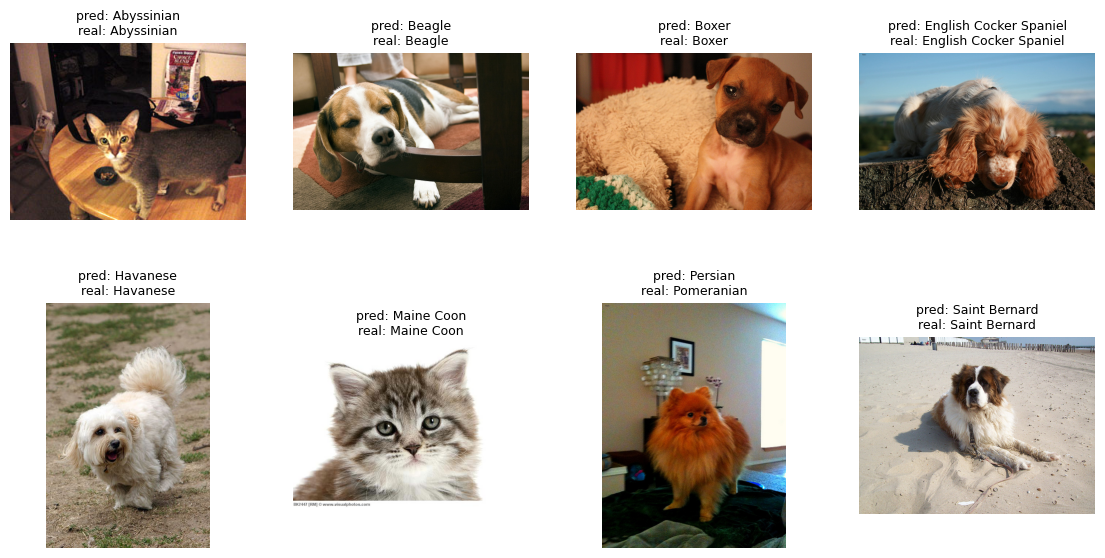

In [26]:
import matplotlib.pyplot as plt

raw_test = datasets.OxfordIIITPet(root="data", split="test" )

model.eval()
fig, axes = plt.subplots(2,4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image, label = test_data[i * 400]
    with torch.no_grad():
      pred = model (image.unsqueeze(0).to(device)).argmax(1).item()
    raw_image, _ = raw_test[i * 400]
    ax.imshow(raw_image)
    ax.set_title(f"pred: {test_data.classes[pred]}\nreal: {test_data.classes[label]}", fontsize=9)
    ax.axis("off")

plt.show()





## Which Breeds Get Confused
Counting the most common mix-ups to see where the model struggles.

In [27]:
from collections import Counter

model.eval()
mistakes = Counter()

with torch.no_grad():
  for images, labels in test_loader:
      images, labels = images.to(device), labels.to(device)
      predictions = model(images).argmax(1)
      for real, pred in zip(labels.tolist(), predictions.tolist()):
          if real != pred:
             mistakes[(test_data.classes[real], test_data.classes[pred])] +=1

for (real, pred), count in mistakes.most_common(5):
  print(f"{real} mistaken for {pred}: {count} times")
print(sum(mistakes.values()))




American Pit Bull Terrier mistaken for Staffordshire Bull Terrier: 27 times
Basset Hound mistaken for Beagle: 27 times
Ragdoll mistaken for Birman: 24 times
American Pit Bull Terrier mistaken for American Bulldog: 17 times
Staffordshire Bull Terrier mistaken for American Bulldog: 16 times
494


## Key Findings
Got 87% accuracy across 37 breeds by training only the last layer of a pretrained ResNet18. The biggest mix-ups were between look-alike breeds, like American Pit Bull Terrier and Staffordshire Bull Terrier, or Birman and Ragdoll, which people confuse too. Those top pairs are only about 18% of the 485 mistakes though, so the rest are spread out. Next thing to try would be fine-tuning more layers or training longer..